# Ejercicio 1 · Predicción de la pobreza multidimensional municipal con Random Forest

El Índice de Pobreza Multidimensional (IPM) municipal solo se puede calcular con un censo, y el último es el CNPV 2018. Entre censos, las alcaldías y gobernaciones planean con cifras viejas. Este ejercicio pregunta si es posible **aproximar el IPM de un municipio a partir de registros administrativos que sí se actualizan cada año** (afiliación a salud, matrícula escolar, servicios públicos, recaudo tributario) y de una fuente satelital (luces nocturnas VIIRS).

Entrenamos un Random Forest con los 1.121 municipios que tienen datos completos en 2018, lo comparamos con una regresión lineal y revisamos qué variables pesan más y dónde se equivoca el modelo.

**Datos (todos reales, año 2018)**

| Variable | Fuente original |
|---|---|
| IPM municipal (variable objetivo) | DANE, Censo Nacional de Población y Vivienda 2018 |
| Régimen subsidiado, tasa de aseguramiento | Ministerio de Salud, BDUA |
| Matrícula, cobertura neta, deserción, repitencia, reprobación | Ministerio de Educación Nacional (datos.gov.co) |
| Cobertura de acueducto, alcantarillado y aseo | Registros de servicios públicos domiciliarios |
| Cobertura de energía rural (ICEE) | UPME |
| Mortalidad infantil y materna | DANE, estadísticas vitales |
| Recaudo de ICA per cápita | Ejecuciones presupuestales municipales |
| Luces nocturnas (radiancia media) | NASA/NOAA VIIRS vía Google Earth Engine |

La base consolidada proviene del repositorio público del proyecto *SAE Pobreza 2026* (Salgado, Caicedo y Trochez, Maestría en Ciencia de Datos, PUJ Cali) y se depuró para este ejercicio.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42

def encuadre(ax):
    """Encuadra el mapa en Colombia continental (San Andrés queda fuera del recuadro)."""
    ax.set_xlim(-79.3, -66.7); ax.set_ylim(-4.4, 12.6); ax.set_axis_off()

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Carga y exploración

In [3]:
df = pd.read_csv(DATOS / 'ej1_ipm_covariables_2018.csv')
print(df.shape)
df.head()

(1121, 23)


,cod_mpio,cod_depto,municipio,departamento,region,ipm,poblacion,pct_regimen_subsidiado,tasa_aseguramiento,tasa_matriculacion_5_16,...,repitencia,reprobacion,cobertura_acueducto,cobertura_alcantarillado,cobertura_aseo,cobertura_energia_rural,mortalidad_infantil,razon_mortalidad_materna,recaudo_ica_pc,luces_nocturnas
0,5001,5,Medellín,Antioquia,Andina,12.8,2427133.0,0.255567,1.000000,0.970671,...,3.8112,9.7624,97.260,95.290,94.670,100.0000,7.104992,29.450744,0.275536,13.795778
1,5002,5,Abejorral,Antioquia,Andina,40.6,20368.0,0.850278,0.811273,0.762192,...,4.2615,5.6315,15.710,15.710,15.710,97.0681,12.820513,0.000000,0.030329,0.298493
2,5004,5,Abriaquí,Antioquia,Andina,34.8,2718.0,0.832339,0.678072,0.675048,...,2.9650,0.0000,39.040,39.040,39.040,85.1163,0.000000,0.000000,0.006023,0.188110
3,5021,5,Alejandría,Antioquia,Andina,31.9,4642.0,0.861133,0.802025,0.661074,...,3.2841,0.0000,39.360,32.560,33.400,98.4174,0.000000,0.000000,0.088564,0.268736
4,5030,5,Amagá,Antioquia,Andina,22.9,30230.0,0.461163,0.832584,0.813117,...,4.3757,13.8603,64.326,60.184,65.782,98.9763,3.215434,0.000000,0.114252,0.985556


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cod_mpio,1121.0,38666.50,26534.11,5001.00,15676.00,25839.00,66456.00,99773.00
cod_depto,1121.0,38.23,26.55,5.00,15.00,25.00,66.00,99.00
ipm,1121.0,41.74,17.28,4.50,30.20,40.80,52.60,98.50
poblacion,1121.0,43048.59,253383.19,270.00,6555.00,12802.00,26959.00,7391056.00
pct_regimen_subsidiado,1121.0,0.82,0.20,0.00,0.77,0.91,0.95,1.00
tasa_aseguramiento,1121.0,0.88,0.15,0.00,0.81,0.91,1.00,1.00
tasa_matriculacion_5_16,1121.0,0.88,0.15,0.00,0.81,0.89,0.97,2.02
cobertura_neta_educ,1121.0,88.04,14.91,0.00,80.56,89.19,96.45,199.98
cobertura_neta_media,1121.0,40.95,15.15,0.00,31.72,40.80,50.36,105.65
desercion_escolar,1121.0,2.82,1.93,0.00,1.57,2.58,3.90,15.52


El IPM municipal va de menos de 5 % (municipios del eje urbano andino) a casi 100 % (municipios dispersos de la Amazonía y el Pacífico). La media simple ronda el 42 %, muy por encima del IPM nacional de 2018 (19,6 %), porque aquí cada municipio pesa lo mismo sin importar su población.

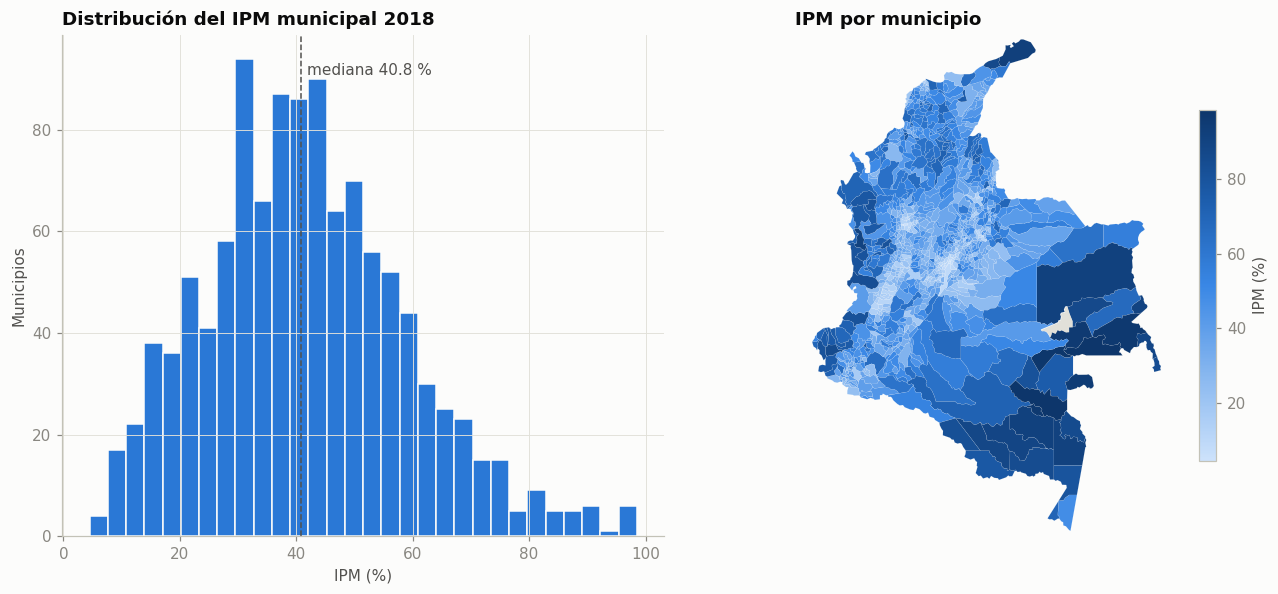

In [5]:
mapa = gpd.read_file(DATOS / 'municipios_colombia.geojson').merge(df, on='cod_mpio', how='left')

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={'width_ratios': [1, 1.1]})
ax[0].hist(df.ipm, bins=30, color=AZUL, edgecolor='#fcfcfb', linewidth=1)
ax[0].axvline(df.ipm.median(), color=TINTA2, ls='--', lw=1)
ax[0].text(df.ipm.median() + 1, ax[0].get_ylim()[1] * 0.92, f'mediana {df.ipm.median():.1f} %', color=TINTA2)
ax[0].set(title='Distribución del IPM municipal 2018', xlabel='IPM (%)', ylabel='Municipios')
mapa.plot(column='ipm', cmap=SEQ, ax=ax[1], legend=True, linewidth=0.05, edgecolor='white',
          missing_kwds={'color': '#e1e0d9'}, legend_kwds={'label': 'IPM (%)', 'shrink': 0.7})
ax[1].set_title('IPM por municipio'); encuadre(ax[1])
plt.tight_layout(); plt.show()

La pobreza tiene un patrón geográfico claro: centro andino con IPM bajo y periferias (Caribe rural, Pacífico, Amazonía, Orinoquía oriental) con IPM alto. Esa estructura espacial la vamos a tener en cuenta al validar el modelo.

¿Qué tan asociadas están las variables candidatas con el IPM?

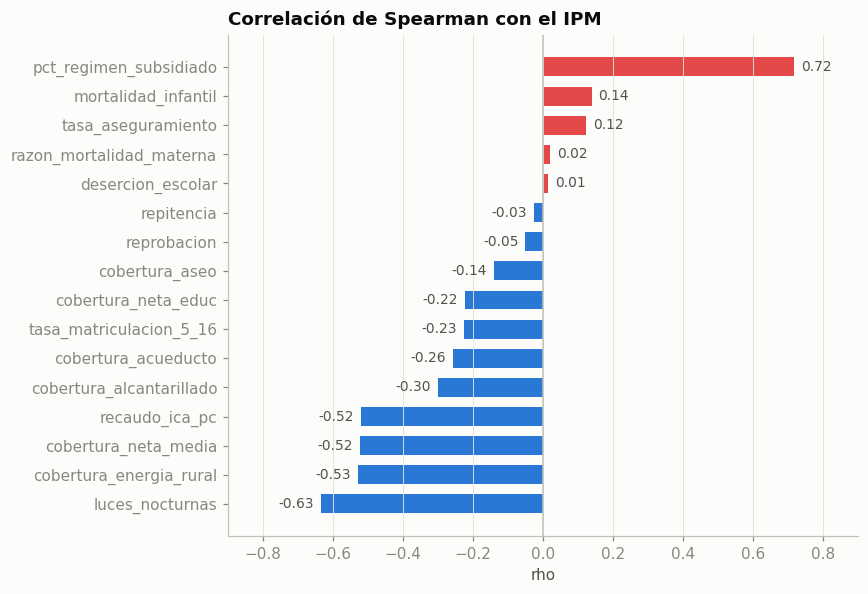

In [6]:
predictoras = ['pct_regimen_subsidiado', 'tasa_aseguramiento', 'tasa_matriculacion_5_16', 'cobertura_neta_educ',
               'cobertura_neta_media', 'desercion_escolar', 'repitencia', 'reprobacion', 'cobertura_acueducto',
               'cobertura_alcantarillado', 'cobertura_aseo', 'cobertura_energia_rural', 'mortalidad_infantil',
               'razon_mortalidad_materna', 'recaudo_ica_pc', 'luces_nocturnas']

corr = df[predictoras + ['ipm']].corr(method='spearman')['ipm'].drop('ipm').sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(corr.index, corr.values, color=[ROJO if v > 0 else AZUL for v in corr.values], height=0.65)
ax.axvline(0, color='#c3c2b7', lw=1)
for i, v in enumerate(corr.values):
    ax.text(v + (0.02 if v > 0 else -0.02), i, f'{v:.2f}', va='center', ha='left' if v > 0 else 'right', color=TINTA2, fontsize=9)
ax.set(title='Correlación de Spearman con el IPM', xlabel='rho', xlim=(-0.9, 0.9))
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

Las asociaciones más fuertes son intuitivas: más afiliados al régimen subsidiado y más pobreza; más luz nocturna, más cobertura en educación media y más recaudo de ICA, menos pobreza. Varias variables educativas (deserción, repitencia) casi no se asocian de forma lineal con el IPM. Un Random Forest puede capturar relaciones no lineales e interacciones que la correlación no ve.

## 2. Preparación de los datos

Transformamos la población a logaritmo (va de 270 a 7,4 millones de habitantes) y agregamos la región natural como variables indicadoras. Luego separamos 20 % de los municipios como conjunto de prueba, estratificando por región para que todas estén representadas.

In [7]:
X = df[predictoras].copy()
X['log_poblacion'] = np.log(df.poblacion.fillna(df.poblacion.median()))
X = pd.concat([X, pd.get_dummies(df.region, prefix='reg', dtype=int)], axis=1)
y = df.ipm

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=df.region)
print(f'Entrenamiento: {len(X_tr)} municipios · Prueba: {len(X_te)} municipios · {X.shape[1]} predictoras')

Entrenamiento: 896 municipios · Prueba: 225 municipios · 22 predictoras


## 3. Línea base y Random Forest inicial

Antes de celebrar cualquier resultado necesitamos un punto de comparación. Usamos una regresión lineal múltiple con las mismas variables.

In [8]:
def metricas(nombre, y_real, y_pred):
    return {'modelo': nombre, 'R2': r2_score(y_real, y_pred),
            'MAE': mean_absolute_error(y_real, y_pred), 'RMSE': root_mean_squared_error(y_real, y_pred)}

lineal = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
rf0 = RandomForestRegressor(n_estimators=500, random_state=SEMILLA, n_jobs=-1).fit(X_tr, y_tr)

pd.DataFrame([metricas('Regresión lineal', y_te, lineal.predict(X_te)),
              metricas('Random Forest (por defecto)', y_te, rf0.predict(X_te))]).round(3)

,modelo,R2,MAE,RMSE
0,Regresión lineal,0.613,8.131,10.390
1,Random Forest (por defecto),0.811,5.599,7.263


Sin ajustar nada, el Random Forest ya explica bastante más varianza del IPM que la regresión lineal en municipios que no vio durante el entrenamiento (R² de 0,81 frente a 0,61) y reduce el error absoluto medio de unos 8 a unos 5,6 puntos de IPM.

## 4. Ajuste de hiperparámetros

Buscamos una mejor combinación con validación cruzada de 5 particiones sobre el conjunto de entrenamiento. Los hiperparámetros que más importan en un Random Forest son cuántas variables considera en cada división (`max_features`), qué tan profundos crecen los árboles y el tamaño mínimo de las hojas.

In [9]:
espacio = {
    'n_estimators': [300, 500, 800],
    'max_features': [0.2, 0.33, 0.5, 0.7, 1.0],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
}
busqueda = RandomizedSearchCV(RandomForestRegressor(random_state=SEMILLA, n_jobs=-1), espacio, n_iter=25,
                              cv=KFold(5, shuffle=True, random_state=SEMILLA), scoring='r2', random_state=SEMILLA)
busqueda.fit(X_tr, y_tr)
print('Mejores hiperparámetros:', busqueda.best_params_)
print(f'R2 promedio en validación cruzada: {busqueda.best_score_:.3f}')
rf = busqueda.best_estimator_

Mejores hiperparámetros: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 10}
R2 promedio en validación cruzada: 0.823


In [10]:
pred_te = rf.predict(X_te)
tabla = pd.DataFrame([metricas('Regresión lineal', y_te, lineal.predict(X_te)),
                      metricas('Random Forest (por defecto)', y_te, rf0.predict(X_te)),
                      metricas('Random Forest (ajustado)', y_te, pred_te)]).round(3)
tabla

,modelo,R2,MAE,RMSE
0,Regresión lineal,0.613,8.131,10.390
1,Random Forest (por defecto),0.811,5.599,7.263
2,Random Forest (ajustado),0.811,5.618,7.274


El ajuste casi no cambia el resultado en prueba. Es una lección útil: el Random Forest es poco sensible a sus hiperparámetros, y los valores por defecto suelen quedar muy cerca del óptimo. La búsqueda sirve más para confirmar que no estamos dejando desempeño sobre la mesa que para ganar puntos.

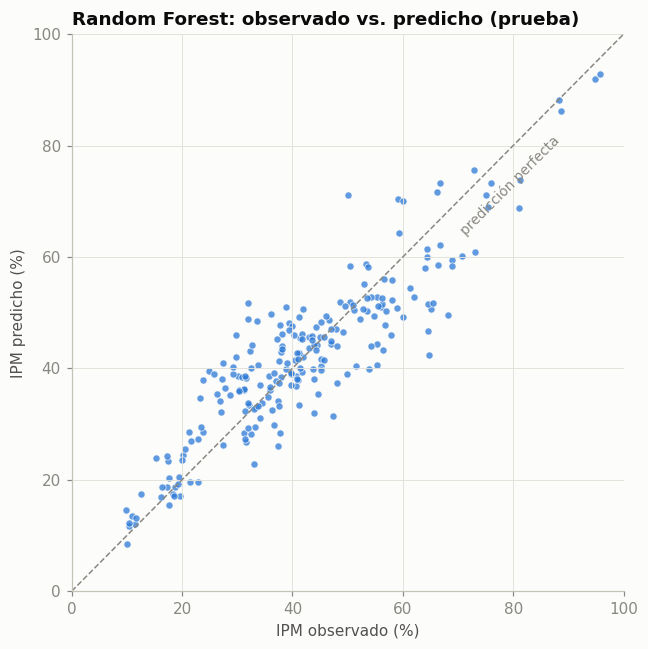

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_te, pred_te, s=22, color=AZUL, alpha=0.75, edgecolor='#fcfcfb', linewidth=0.6)
ax.plot([0, 100], [0, 100], color=GRIS, ls='--', lw=1)
ax.text(70, 64, 'predicción perfecta', color=GRIS, rotation=45, fontsize=9)
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel='IPM observado (%)', ylabel='IPM predicho (%)',
       title='Random Forest: observado vs. predicho (prueba)')
plt.tight_layout(); plt.show()

El modelo acierta bien en el centro de la distribución y tiende a "encoger" los extremos: sobrestima el IPM de los municipios menos pobres y subestima el de los más pobres. Es un sesgo típico del Random Forest, que predice promedios de hojas y no puede salirse del rango que vio en el entrenamiento.

## 5. ¿La validación aleatoria es demasiado optimista?

Los municipios vecinos se parecen entre sí. Si en el entrenamiento hay municipios del mismo departamento que los de prueba, el modelo puede "aprender la geografía" más que la relación entre variables. Una prueba más exigente es la **validación agrupada por departamento**: en cada ronda se dejan por fuera departamentos completos.

In [12]:
modelo = RandomForestRegressor(**busqueda.best_params_, random_state=SEMILLA, n_jobs=-1)
r2_aleatoria = cross_val_score(modelo, X, y, cv=KFold(5, shuffle=True, random_state=SEMILLA), scoring='r2')
r2_espacial = cross_val_score(modelo, X, y, cv=GroupKFold(5), groups=df.cod_depto, scoring='r2')
print(f'R2 con particiones aleatorias:        {r2_aleatoria.mean():.3f} ± {r2_aleatoria.std():.3f}')
print(f'R2 dejando departamentos por fuera:   {r2_espacial.mean():.3f} ± {r2_espacial.std():.3f}')

R2 con particiones aleatorias:        0.826 ± 0.024
R2 dejando departamentos por fuera:   0.675 ± 0.129


El R² baja de 0,83 a cerca de 0,68 cuando se dejan departamentos completos por fuera, y la variación entre rondas crece. Esa caída mide cuánto del desempeño dependía de tener vecinos en el entrenamiento. Es la cifra honesta si el modelo se va a usar en territorios donde no hay información de referencia.

## 6. ¿Qué variables usa el modelo?

La importancia por impureza (la que trae `feature_importances_`) favorece variables continuas con muchos valores posibles. La **importancia por permutación** sobre el conjunto de prueba es más confiable: mide cuánto empeora el R² cuando se desordena al azar cada variable.

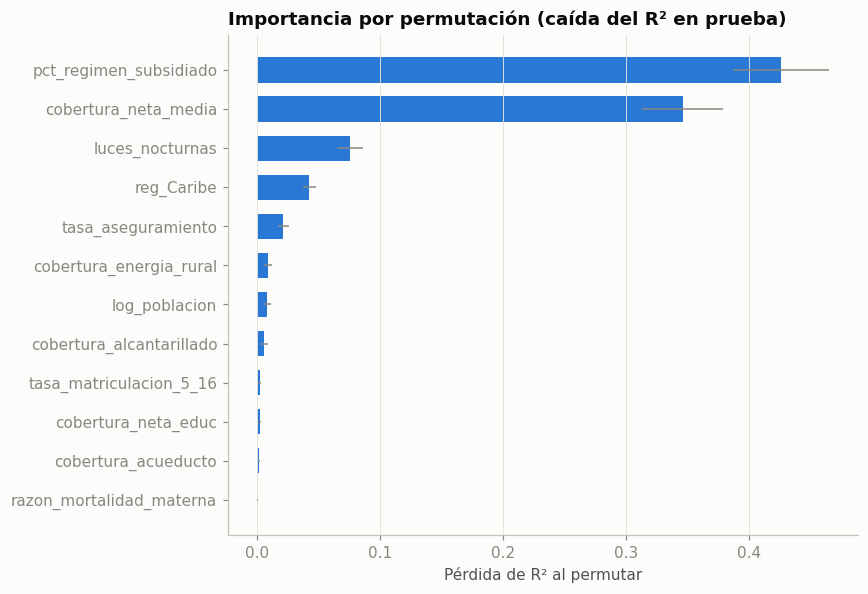

,impureza,permutacion,perm_sd
pct_regimen_subsidiado,0.403,0.426,0.039
cobertura_neta_media,0.269,0.346,0.033
luces_nocturnas,0.113,0.076,0.010
reg_Caribe,0.025,0.043,0.006
tasa_aseguramiento,0.027,0.022,0.004
cobertura_energia_rural,0.033,0.009,0.003
log_poblacion,0.018,0.008,0.003
cobertura_alcantarillado,0.014,0.006,0.003
tasa_matriculacion_5_16,0.011,0.003,0.001
cobertura_neta_educ,0.011,0.003,0.001


In [13]:
perm = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=SEMILLA, scoring='r2')
imp = pd.DataFrame({'impureza': rf.feature_importances_, 'permutacion': perm.importances_mean,
                    'perm_sd': perm.importances_std}, index=X.columns).sort_values('permutacion')
top = imp.tail(12)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.permutacion, xerr=top.perm_sd, color=AZUL, height=0.65, error_kw={'ecolor': GRIS, 'lw': 1})
ax.set(title='Importancia por permutación (caída del R² en prueba)', xlabel='Pérdida de R² al permutar')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
imp.sort_values('permutacion', ascending=False).round(3).head(10)

Tres variables concentran casi toda la capacidad predictiva: el peso del régimen subsidiado en salud (una aproximación a la población sin empleo formal), la cobertura neta en educación media y la intensidad de luces nocturnas (actividad económica y urbanización). Las gráficas de dependencia parcial muestran la forma de esa relación, manteniendo lo demás constante.

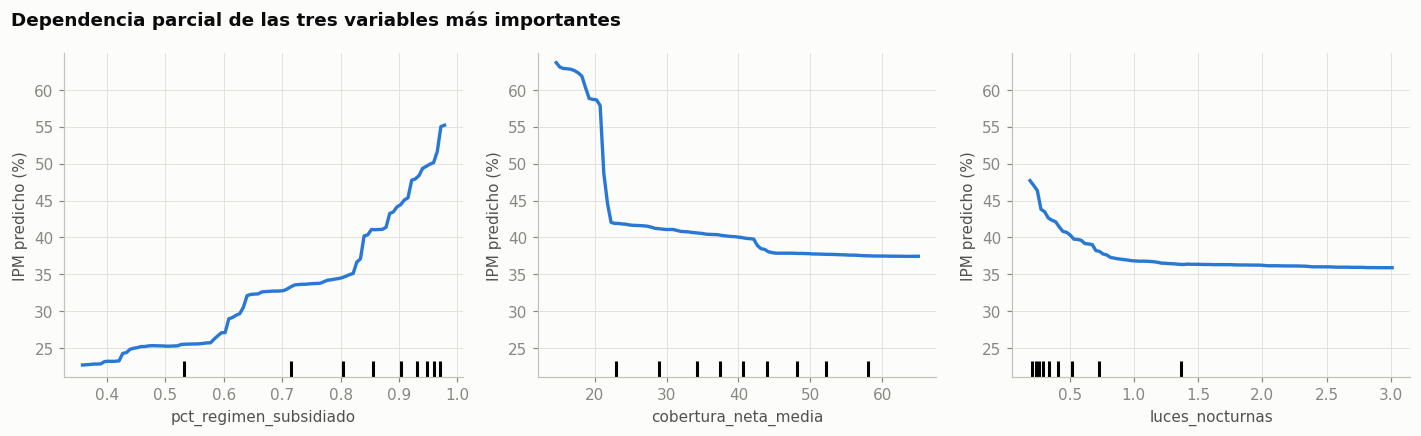

In [14]:
top3 = imp.sort_values('permutacion', ascending=False).index[:3].tolist()
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
PartialDependenceDisplay.from_estimator(rf, X_tr, top3, ax=ax, line_kw={'color': AZUL, 'lw': 2.2})
for a in ax: a.set_ylabel('IPM predicho (%)')
fig.suptitle('Dependencia parcial de las tres variables más importantes', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

Ninguna de las tres relaciones es lineal. El IPM predicho sube poco mientras el régimen subsidiado está por debajo del 80 % de los afiliados y se dispara por encima de ese nivel. En educación media hay un umbral cerca del 20 % de cobertura neta: por debajo, el IPM predicho salta más de 15 puntos. Con las luces nocturnas casi todo el efecto está en el tramo más oscuro; por encima de una radiancia de 1, más luz ya no cambia la predicción. Estos umbrales explican buena parte de la ventaja del Random Forest sobre la regresión lineal.

## 7. ¿Dónde se equivoca el modelo?

Obtenemos una predicción "fuera de muestra" para cada municipio con validación cruzada y mapeamos los residuos (observado menos predicho). En rojo, municipios más pobres de lo que el modelo espera; en azul, menos pobres.

           sesgo medio  error absoluto medio  municipios
region                                                  
Amazonía          0.15                  5.48          58
Andina           -0.03                  5.11         629
Caribe            1.84                  6.06         197
Orinoquía        -0.92                  5.48          59
Pacífica         -1.94                  6.92         178


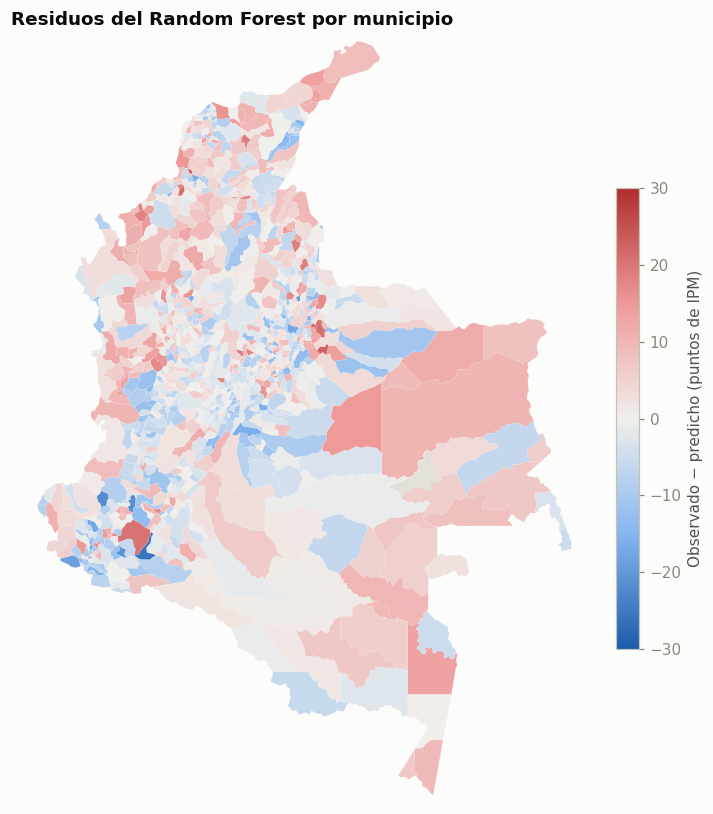

In [15]:
df['ipm_pred'] = cross_val_predict(modelo, X, y, cv=KFold(5, shuffle=True, random_state=SEMILLA))
df['residuo'] = df.ipm - df.ipm_pred

print(df.groupby('region').residuo.agg(['mean', lambda s: s.abs().mean(), 'count'])
        .set_axis(['sesgo medio', 'error absoluto medio', 'municipios'], axis=1).round(2))

mapa = gpd.read_file(DATOS / 'municipios_colombia.geojson').merge(df[['cod_mpio', 'residuo']], on='cod_mpio', how='left')
fig, ax = plt.subplots(figsize=(7, 7.5))
lim = 30
mapa.plot(column='residuo', cmap=DIV, vmin=-lim, vmax=lim, ax=ax, legend=True, linewidth=0.05, edgecolor='white',
          missing_kwds={'color': '#e1e0d9'}, legend_kwds={'label': 'Observado − predicho (puntos de IPM)', 'shrink': 0.6})
ax.set_title('Residuos del Random Forest por municipio'); encuadre(ax)
plt.tight_layout(); plt.show()

In [16]:
cols = ['municipio', 'departamento', 'ipm', 'ipm_pred', 'residuo']
print('Municipios más pobres de lo esperado')
display(df.nlargest(8, 'residuo')[cols].round(1))
print('Municipios menos pobres de lo esperado')
display(df.nsmallest(8, 'residuo')[cols].round(1))

Municipios más pobres de lo esperado


,municipio,departamento,ipm,ipm_pred,residuo
938,Chalán,Sucre,73.9,51.4,22.5
264,Paya,Boyacá,68.2,45.9,22.3
240,Jericó,Boyacá,64.7,43.2,21.5
449,San Andrés De Sotavento,Córdoba,76.3,54.9,21.4
213,Chita,Boyacá,69.1,48.4,20.7
393,Santa Rosa,Cauca,66.1,45.9,20.2
456,Tuchín,Córdoba,78.0,58.9,19.1
657,Algarrobo,Magdalena,57.3,38.4,18.9


Municipios menos pobres de lo esperado


,municipio,departamento,ipm,ipm_pred,residuo
386,Piamonte,Cauca,44.0,70.0,-26.0
363,Argelia,Cauca,50.1,71.8,-21.7
395,Sotará - Paispamba,Cauca,32.3,53.7,-21.4
1081,San Francisco,Putumayo,23.5,44.2,-20.7
728,Cumbal,Nariño,28.6,47.6,-19.0
858,Cepitá,Santander,32.0,50.8,-18.8
874,Encino,Santander,32.0,49.5,-17.5
758,Policarpa,Nariño,38.7,56.0,-17.3


Los errores no son aleatorios. El modelo subestima la pobreza en el Caribe (sesgo medio de casi +2 puntos) y la sobrestima en el Pacífico (cerca de −2), que es además la región con mayor error absoluto. Entre los municipios más pobres de lo esperado aparecen municipios del resguardo zenú en Córdoba y Sucre (Tuchín, San Andrés de Sotavento, Chalán) y municipios de alta montaña en Boyacá (Paya, Chita, Jericó). Entre los menos pobres de lo esperado dominan municipios de Cauca y Nariño. Una hipótesis para discutir en clase: en esos territorios los registros administrativos (afiliación, matrícula, servicios) reflejan mal condiciones como la calidad de la vivienda o el tipo de trabajo, que pesan mucho en el IPM. La lista de residuos es en sí misma un resultado útil, porque señala dónde el modelo no basta y hace falta información de campo.

## 8. Conclusiones

Con registros administrativos y una variable satelital, un Random Forest explica alrededor del 81 % de la variación del IPM municipal en municipios no vistos, frente al 61 % de la regresión lineal. La ventaja viene de relaciones con umbrales, sobre todo en régimen subsidiado, cobertura de educación media y luces nocturnas. El desempeño cae a cerca de 0,68 cuando se predicen departamentos completos, y el modelo comprime los extremos, así que sirve para aproximar niveles de pobreza entre censos pero no para ordenar finamente a los municipios más pobres.

## Retos para los estudiantes

1. Cambie la variable objetivo por `desercion_escolar` (quítela de las predictoras). ¿El Random Forest sigue superando a la regresión lineal? ¿Por qué la deserción es más difícil de predecir?
2. Elimine `luces_nocturnas` y compare el R². ¿Cuánto aporta la información satelital?
3. Reemplace el Random Forest por `GradientBoostingRegressor` o `XGBRegressor` y compare con la validación agrupada por departamento.
4. Con las predicciones fuera de muestra, identifique los diez municipios de su departamento con mayor residuo y proponga una explicación.